# Temporal Sweet-Spot Experiment — LOBO + Prospective Sep-4/5/6 Rankings

**Optimized final version**

This notebook follows the established Model B/C workflow:

1. Read calibration history directly from **Railway MySQL** through the existing `database.py`.
2. Build the same leakage-safe 17 historical features.
3. Evaluate **1-day, 3-day, 7-day, and 30-day** training windows.
4. For every window, run **3-fold Leave-One-Backend-Out (LOBO)** for **XGBoost and Random Forest**.
5. Select the better algorithm for each window by **mean LOBO AUC**.
6. Calculate the established **2,000-iteration cluster-bootstrap 95% CI** for the selected algorithm.
7. Save LOBO metrics, bootstrap CIs, ROC figures, algorithm comparison, and metadata.
8. Generate prospective rankings for **Sep-4, Sep-5, and Sep-6** using only history available before each prediction date.
9. Save exactly **four final Sep-6 model artifacts**, one per temporal window.

The bootstrap keeps the same statistical procedure but uses NumPy arrays rather than repeatedly filtering/concatenating pandas DataFrames inside every iteration.

## 1. Imports and project configuration

In [1]:

from pathlib import Path
import sys
import json
import pickle
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, f1_score,
    matthews_corrcoef, accuracy_score, roc_curve
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "database.py").exists() and (PROJECT_ROOT.parent / "database.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "database.py").exists():
    raise FileNotFoundError(
        "database.py was not found. Set PROJECT_ROOT to the Qubit Telemetry project root."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import database

RESULTS_DIR = PROJECT_ROOT / "results" / "temporal_sweet_spot"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models" / "temporal_sweet_spot"

for d in [RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULTS_DIR:", RESULTS_DIR)
print("MODELS_DIR:", MODELS_DIR)


PROJECT_ROOT: D:\Downloads\uday projects\ibm_quantum
RESULTS_DIR: D:\Downloads\uday projects\ibm_quantum\results\temporal_sweet_spot
MODELS_DIR: D:\Downloads\uday projects\ibm_quantum\models\temporal_sweet_spot


## 2. Experimental constants

In [2]:

WINDOWS = {
    "1day": 1,
    "3day": 3,
    "7day": 7,
    "30day": 30,
}

PREDICTION_DATES = [
    pd.Timestamp("2026-09-04").date(),
    pd.Timestamp("2026-09-05").date(),
    pd.Timestamp("2026-09-06").date(),
]

LOBO_CUTOFF = pd.Timestamp("2026-09-04").date()
SEP6_DATE = pd.Timestamp("2026-09-06").date()

T1_THRESH = 100.0
T2_THRESH = 50.0
RE_THRESH = 0.05

HIST_FEATURES = [
    "hist_T1_mean", "hist_T1_std", "hist_T1_min", "hist_T1_max",
    "hist_T2_mean", "hist_T2_std", "hist_T2_min", "hist_T2_max",
    "hist_RE_mean", "hist_RE_std", "hist_RE_min", "hist_RE_max",
    "prev_T1", "prev_T2", "prev_RE",
    "hist_coherence_product", "hist_t2_t1_ratio",
]

XGB_PARAMS = dict(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    verbosity=0,
)

RF_PARAMS = dict(
    n_estimators=200,
    max_depth=8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

EXPECTED_BACKENDS = {"ibm_fez", "ibm_kingston", "ibm_marrakesh"}

print("Windows:", WINDOWS)
print("Prediction dates:", PREDICTION_DATES)
print("Feature count:", len(HIST_FEATURES))


Windows: {'1day': 1, '3day': 3, '7day': 7, '30day': 30}
Prediction dates: [datetime.date(2026, 9, 4), datetime.date(2026, 9, 5), datetime.date(2026, 9, 6)]
Feature count: 17


## 3. Load calibration history from Railway MySQL

**No CSV is used as the source of truth.** The existing `database.get_connection()` is used.

In [3]:

conn = database.get_connection()

try:
    raw = pd.read_sql(
        """
        SELECT
            backend,
            qubit,
            snapshot_date,
            T1_us,
            T2_us,
            readout_error
        FROM calibration_history
        ORDER BY backend, qubit, snapshot_date
        """,
        conn,
    )
finally:
    conn.close()

if raw.empty:
    raise RuntimeError("calibration_history returned zero rows.")

raw["snapshot_date"] = pd.to_datetime(raw["snapshot_date"]).dt.date
raw["qubit"] = pd.to_numeric(raw["qubit"], errors="coerce")

for c in ["T1_us", "T2_us", "readout_error"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

raw = raw.dropna(
    subset=["backend", "qubit", "snapshot_date", "T1_us", "T2_us", "readout_error"]
).copy()

raw["qubit"] = raw["qubit"].astype(int)

raw = (
    raw.sort_values(["backend", "qubit", "snapshot_date"])
       .drop_duplicates(["backend", "qubit", "snapshot_date"], keep="last")
       .reset_index(drop=True)
)

print("Rows:", f"{len(raw):,}")
print("Backends:", sorted(raw["backend"].unique()))
print("Date range:", raw["snapshot_date"].min(), "→", raw["snapshot_date"].max())
print("Observed dates:", raw["snapshot_date"].nunique())

unexpected = set(raw["backend"].unique()) - EXPECTED_BACKENDS
if unexpected:
    raise ValueError(f"Unexpected backend(s): {sorted(unexpected)}")

display(
    raw.groupby("backend")
       .agg(
           rows=("qubit", "size"),
           qubits=("qubit", "nunique"),
           first_date=("snapshot_date", "min"),
           last_date=("snapshot_date", "max"),
           observed_dates=("snapshot_date", "nunique"),
       )
       .reset_index()
)


Rows: 26,562
Backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Date range: 2026-07-13 → 2026-09-07
Observed dates: 57


,backend,rows,qubits,first_date,last_date,observed_dates
0,ibm_fez,8835,155,2026-07-13,2026-09-07,57
1,ibm_kingston,8835,155,2026-07-13,2026-09-07,57
2,ibm_marrakesh,8892,156,2026-07-13,2026-09-07,57


## 4. Verify the requested prospective dates

In [4]:

available_dates = set(raw["snapshot_date"].unique())

date_check = pd.DataFrame({"prediction_date": PREDICTION_DATES})
date_check["present"] = date_check["prediction_date"].isin(available_dates)
display(date_check)

missing = date_check.loc[~date_check["present"], "prediction_date"].tolist()
if missing:
    raise ValueError(
        f"Requested prediction date(s) are missing from Railway MySQL: {missing}"
    )


,prediction_date,present
0,2026-09-04,True
1,2026-09-05,True
2,2026-09-06,True


## 5. Leakage-safe feature construction

For every backend/qubit series, every historical statistic is based on `shift(1)` before the expanding calculation. Therefore the feature vector for date D contains only observations before D.

The current row's T1/T2/readout values are used only for its label, never as model features.

In [5]:

def add_historical_features(df):
    out = df.copy()

    out["snapshot_id"] = (
        out.groupby(["backend", "qubit"])["snapshot_date"]
           .transform(lambda x: pd.factorize(x)[0])
    )

    for col, alias in [
        ("T1_us", "T1"),
        ("T2_us", "T2"),
        ("readout_error", "RE"),
    ]:
        g = out.groupby(["backend", "qubit"])[col]

        out[f"hist_{alias}_mean"] = g.transform(
            lambda x: x.shift(1).expanding().mean()
        )
        out[f"hist_{alias}_std"] = g.transform(
            lambda x: x.shift(1).expanding().std()
        )
        out[f"hist_{alias}_min"] = g.transform(
            lambda x: x.shift(1).expanding().min()
        )
        out[f"hist_{alias}_max"] = g.transform(
            lambda x: x.shift(1).expanding().max()
        )
        out[f"prev_{alias}"] = g.transform(lambda x: x.shift(1))

    out["hist_coherence_product"] = out["hist_T1_mean"] * out["hist_T2_mean"]
    out["hist_t2_t1_ratio"] = out["hist_T2_mean"] / (out["hist_T1_mean"] + 1e-9)

    out["label"] = (
        (out["T1_us"] > T1_THRESH)
        & (out["T2_us"] > T2_THRESH)
        & (out["readout_error"] < RE_THRESH)
    ).astype(int)

    return out.sort_values(
        ["snapshot_date", "backend", "qubit"]
    ).reset_index(drop=True)

featured = add_historical_features(raw)

assert all(c in featured.columns for c in HIST_FEATURES)
print("Feature construction complete.")
print("Complete feature rows:", f"{featured[HIST_FEATURES].notna().all(axis=1).sum():,}")


Feature construction complete.
Complete feature rows: 25,630


## 6. Window selection

In [6]:

def observed_dates_before(df, cutoff_date):
    return sorted(d for d in df["snapshot_date"].unique() if d < cutoff_date)

def select_window(df, cutoff_date, window_days):
    dates = observed_dates_before(df, cutoff_date)
    if len(dates) < window_days:
        raise ValueError(
            f"Only {len(dates)} observed dates exist before {cutoff_date}; "
            f"{window_days} required."
        )

    dates_used = dates[-window_days:]
    data = df[
        df["snapshot_date"].isin(dates_used)
        & df[HIST_FEATURES].notna().all(axis=1)
    ].copy()

    if set(data["backend"].unique()) != EXPECTED_BACKENDS:
        raise ValueError(
            f"Window before {cutoff_date} does not contain all expected backends. "
            f"Found: {sorted(data['backend'].unique())}"
        )

    return data, dates_used

def prediction_rows(df, prediction_date):
    pred = df[
        (df["snapshot_date"] == prediction_date)
        & df[HIST_FEATURES].notna().all(axis=1)
    ].copy()

    if pred.empty:
        raise ValueError(f"No complete prediction rows for {prediction_date}.")
    return pred


## 7. LOBO evaluator

For each window and algorithm:

- FEZ held out → train Kingston + Marrakesh
- Kingston held out → train FEZ + Marrakesh
- Marrakesh held out → train FEZ + Kingston

The held-out backend is never included in its fold's training data.

In [7]:

def build_model(model_name, params):
    if model_name == "XGBoost":
        return XGBClassifier(**params)
    if model_name == "RandomForest":
        return RandomForestClassifier(**params)
    raise ValueError(f"Unknown model: {model_name}")

def run_lobo(data, model_name, params):
    rows = []
    predictions = {}

    backends = sorted(data["backend"].unique())
    if set(backends) != EXPECTED_BACKENDS:
        raise ValueError(
            f"LOBO requires exactly the expected three backends. Found: {backends}"
        )

    for test_backend in backends:
        train = data[data["backend"] != test_backend]
        test = data[data["backend"] == test_backend]

        if train["label"].nunique() < 2:
            raise ValueError(
                f"{model_name}, held-out={test_backend}: training fold has one class."
            )
        if test["label"].nunique() < 2:
            raise ValueError(
                f"{model_name}, held-out={test_backend}: test fold has one class."
            )

        model = build_model(model_name, params)
        model.fit(train[HIST_FEATURES], train["label"])

        y_true = test["label"].to_numpy(dtype=int)
        y_prob = model.predict_proba(test[HIST_FEATURES])[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)

        rows.append({
            "Model": model_name,
            "Test_Backend": test_backend,
            "Train_Rows": len(train),
            "Test_Rows": len(test),
            "AUC": roc_auc_score(y_true, y_prob),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "MCC": matthews_corrcoef(y_true, y_pred),
        })

        predictions[test_backend] = {
            "y_true": y_true,
            "y_prob": y_prob,
            "y_pred": y_pred,
            "qubit": test["qubit"].to_numpy(dtype=int),
        }

    return pd.DataFrame(rows), predictions


## 8. Run LOBO for all four temporal windows

In [8]:

lobo_results = {}
window_data = {}
window_dates = {}
comparison_rows = []
all_lobo_rows = []

for window_label, window_days in WINDOWS.items():
    data, dates_used = select_window(featured, LOBO_CUTOFF, window_days)
    window_data[window_label] = data
    window_dates[window_label] = dates_used

    print("\n" + "=" * 90)
    print(
        f"WINDOW {window_label}: {dates_used[0]} → {dates_used[-1]} | "
        f"{len(dates_used)} observed dates | {len(data):,} usable rows"
    )
    print("=" * 90)

    xgb_results, xgb_preds = run_lobo(data, "XGBoost", XGB_PARAMS)
    rf_results, rf_preds = run_lobo(data, "RandomForest", RF_PARAMS)

    for algorithm, result_df in [("XGBoost", xgb_results), ("RandomForest", rf_results)]:
        comparison_rows.append({
            "Window": window_label,
            "Window_Dates": f"{dates_used[0]} → {dates_used[-1]}",
            "Algorithm": algorithm,
            "Mean_LOBO_AUC": result_df["AUC"].mean(),
            "Min_LOBO_AUC": result_df["AUC"].min(),
            "Mean_Accuracy": result_df["Accuracy"].mean(),
            "Mean_Balanced_Accuracy": result_df["Balanced_Accuracy"].mean(),
            "Mean_F1": result_df["F1"].mean(),
            "Mean_MCC": result_df["MCC"].mean(),
        })
        temp = result_df.copy()
        temp.insert(0, "Window", window_label)
        temp["Window_Dates"] = f"{dates_used[0]} → {dates_used[-1]}"
        all_lobo_rows.append(temp)

    if xgb_results["AUC"].mean() >= rf_results["AUC"].mean():
        best_name, best_results, best_predictions = "XGBoost", xgb_results, xgb_preds
    else:
        best_name, best_results, best_predictions = "RandomForest", rf_results, rf_preds

    lobo_results[window_label] = {
        "xgb_results": xgb_results,
        "rf_results": rf_results,
        "xgb_predictions": xgb_preds,
        "rf_predictions": rf_preds,
        "best_name": best_name,
        "best_results": best_results,
        "best_predictions": best_predictions,
    }

    print("\nXGBoost:")
    display(xgb_results.round(4))
    print(f"Mean LOBO AUC: {xgb_results['AUC'].mean():.4f}")

    print("\nRandomForest:")
    display(rf_results.round(4))
    print(f"Mean LOBO AUC: {rf_results['AUC'].mean():.4f}")

    print(f"\nSELECTED: {best_name} | Mean LOBO AUC={best_results['AUC'].mean():.4f}")



WINDOW 1day: 2026-09-03 → 2026-09-03 | 1 observed dates | 466 usable rows

XGBoost:


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,XGBoost,ibm_fez,311,155,0.8714,0.8129,0.8080,0.8343,0.6212
1,XGBoost,ibm_kingston,311,155,0.8867,0.8903,0.8134,0.9312,0.6652
2,XGBoost,ibm_marrakesh,310,156,0.8990,0.8141,0.8104,0.8324,0.6271


Mean LOBO AUC: 0.8857

RandomForest:


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,RandomForest,ibm_fez,311,155,0.8706,0.7806,0.7748,0.8068,0.5555
1,RandomForest,ibm_kingston,311,155,0.9064,0.8839,0.7882,0.9280,0.6383
2,RandomForest,ibm_marrakesh,310,156,0.8983,0.8205,0.8123,0.8478,0.6524


Mean LOBO AUC: 0.8918

SELECTED: RandomForest | Mean LOBO AUC=0.8918

WINDOW 3day: 2026-09-01 → 2026-09-03 | 3 observed dates | 1,398 usable rows

XGBoost:


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,XGBoost,ibm_fez,933,465,0.8609,0.7957,0.7855,0.8270,0.5817
1,XGBoost,ibm_kingston,933,465,0.8857,0.8903,0.8129,0.9323,0.6450
2,XGBoost,ibm_marrakesh,930,468,0.8736,0.7842,0.7793,0.8119,0.5767


... (7 outputs left out)

,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,XGBoost,ibm_fez,9330,4650,0.8614,0.7828,0.7775,0.8102,0.5704
1,XGBoost,ibm_kingston,9330,4650,0.9157,0.9110,0.8588,0.9432,0.7381
2,XGBoost,ibm_marrakesh,9300,4680,0.8793,0.7966,0.7944,0.8215,0.6098


Mean LOBO AUC: 0.8855

RandomForest:


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,RandomForest,ibm_fez,9330,4650,0.8649,0.7817,0.7741,0.8165,0.5794
1,RandomForest,ibm_kingston,9330,4650,0.9295,0.9219,0.8580,0.9509,0.7665
2,RandomForest,ibm_marrakesh,9300,4680,0.8873,0.7912,0.7886,0.8210,0.6081


Mean LOBO AUC: 0.8939

SELECTED: RandomForest | Mean LOBO AUC=0.8939


## 9. Save LOBO metrics and algorithm comparison

In [9]:

all_lobo_df = pd.concat(all_lobo_rows, ignore_index=True)
comparison_df = pd.DataFrame(comparison_rows)

best_summary_rows = []
for window_label, result in lobo_results.items():
    r = result["best_results"]
    dates_used = window_dates[window_label]
    best_summary_rows.append({
        "Window": window_label,
        "Window_Dates": f"{dates_used[0]} → {dates_used[-1]}",
        "Selected_Algorithm": result["best_name"],
        "Mean_LOBO_AUC": r["AUC"].mean(),
        "Min_LOBO_AUC": r["AUC"].min(),
        "Mean_Accuracy": r["Accuracy"].mean(),
        "Mean_Balanced_Accuracy": r["Balanced_Accuracy"].mean(),
        "Mean_F1": r["F1"].mean(),
        "Mean_MCC": r["MCC"].mean(),
    })

best_summary_df = pd.DataFrame(best_summary_rows)

all_lobo_df.to_csv(RESULTS_DIR / "temporal_sweet_spot_lobo_all_results.csv", index=False)
comparison_df.to_csv(RESULTS_DIR / "temporal_sweet_spot_algorithm_comparison.csv", index=False)
best_summary_df.to_csv(RESULTS_DIR / "temporal_sweet_spot_selected_window_summary.csv", index=False)

display(best_summary_df.round(4))


,Window,Window_Dates,Selected_Algorithm,Mean_LOBO_AUC,Min_LOBO_AUC,Mean_Accuracy,Mean_Balanced_Accuracy,Mean_F1,Mean_MCC
0,1day,2026-09-03 → 2026-09-03,RandomForest,0.8918,0.8706,0.8283,0.7918,0.8609,0.6154
1,3day,2026-09-01 → 2026-09-03,RandomForest,0.8766,0.8644,0.8256,0.7886,0.8607,0.6110
2,7day,2026-08-28 → 2026-09-03,RandomForest,0.8701,0.8531,0.8248,0.7948,0.8596,0.6244
3,30day,2026-08-05 → 2026-09-03,RandomForest,0.8939,0.8649,0.8316,0.8069,0.8628,0.6513


## 10. LOBO ROC curves

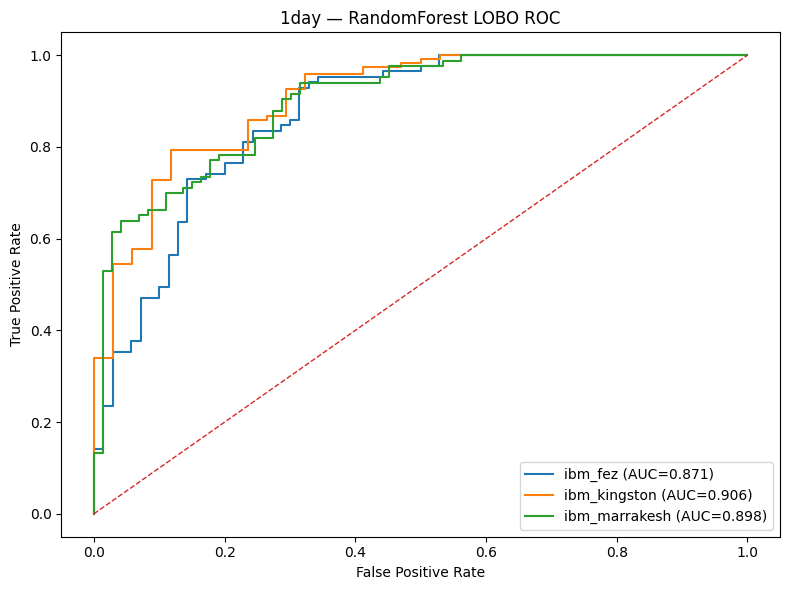

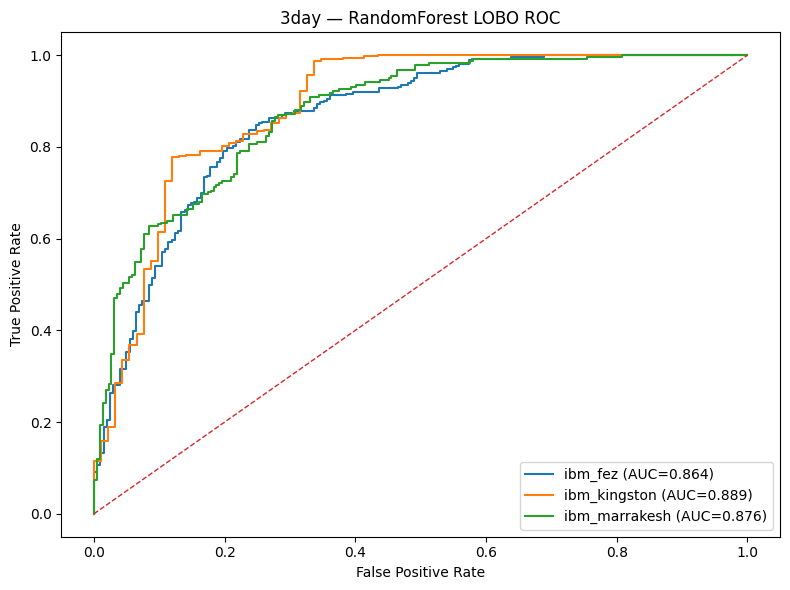

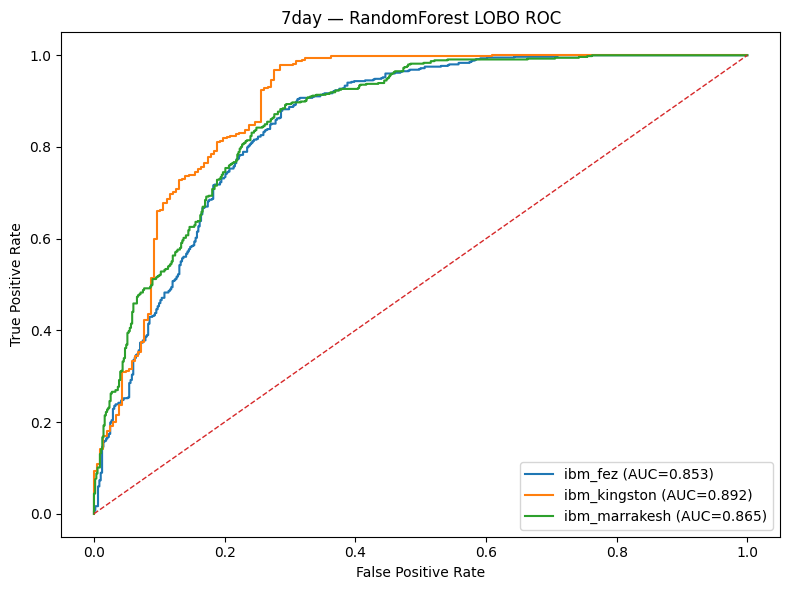

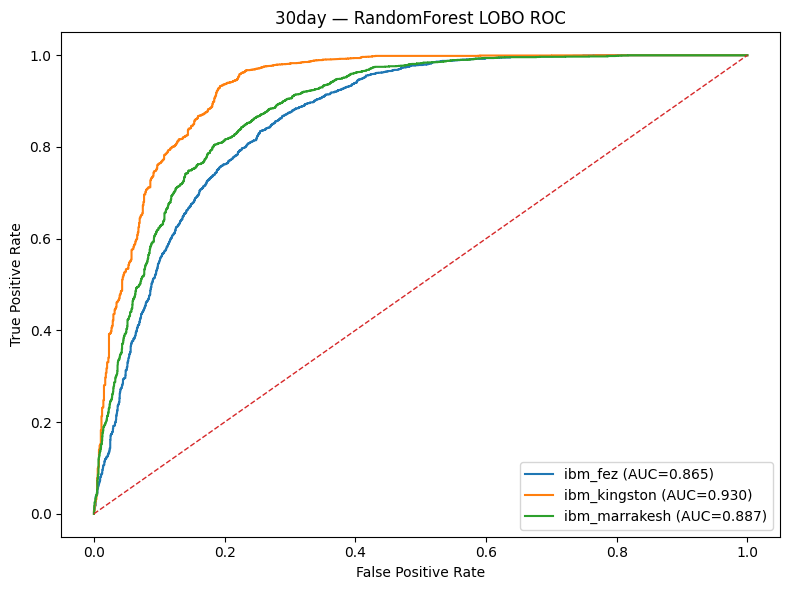

In [10]:

def plot_lobo_roc(result, window_label):
    plt.figure(figsize=(8, 6))
    for backend, p in result["best_predictions"].items():
        fpr, tpr, _ = roc_curve(p["y_true"], p["y_prob"])
        auc = roc_auc_score(p["y_true"], p["y_prob"])
        plt.plot(fpr, tpr, label=f"{backend} (AUC={auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{window_label} — {result['best_name']} LOBO ROC")
    plt.legend()
    plt.tight_layout()

    path = FIGURES_DIR / f"{window_label}_selected_lobo_roc.png"
    plt.savefig(path, dpi=150)
    plt.show()

for window_label, result in lobo_results.items():
    plot_lobo_roc(result, window_label)


## 11. Optimized 2,000-iteration cluster bootstrap

The established method is preserved:

- cluster = physical **qubit**
- sample qubit clusters with replacement
- include all observations for each sampled cluster
- calculate ROC-AUC
- CI = 2.5th and 97.5th percentiles

The optimization removes pandas filtering/concatenation from the hot loop.

In [11]:

def cluster_bootstrap_auc_fast(y, p, clusters, n_boot=2000, seed=42, progress_every=500):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    clusters = np.asarray(clusters)

    observed = roc_auc_score(y, p)

    unique_clusters = np.unique(clusters)
    cluster_y = []
    cluster_p = []

    for c in unique_clusters:
        mask = clusters == c
        cluster_y.append(y[mask])
        cluster_p.append(p[mask])

    rng = np.random.default_rng(seed)
    values = np.empty(n_boot, dtype=np.float64)
    n_clusters = len(unique_clusters)

    for i in range(n_boot):
        sampled_idx = rng.integers(0, n_clusters, size=n_clusters)

        y_sample = np.concatenate([cluster_y[j] for j in sampled_idx])
        p_sample = np.concatenate([cluster_p[j] for j in sampled_idx])

        if np.unique(y_sample).size == 2:
            values[i] = roc_auc_score(y_sample, p_sample)
        else:
            values[i] = np.nan

        if progress_every and ((i + 1) % progress_every == 0):
            print(f"    bootstrap {i + 1:,}/{n_boot:,}")

    values = values[~np.isnan(values)]

    if len(values) < n_boot * 0.95:
        raise RuntimeError(f"Too many invalid bootstrap samples: {len(values)}/{n_boot}")

    return (
        observed,
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5)),
    )


## 12. Run bootstrap CIs

Only the selected algorithm for each window is bootstrapped: 4 windows × 3 held-out backends = 12 bootstrap calculations, each with 2,000 iterations.

In [12]:

bootstrap_rows = []

for window_label, result in lobo_results.items():
    print("\n" + "=" * 90)
    print(
        f"BOOTSTRAP: {window_label} — {result['best_name']} "
        f"(2,000 iterations × 3 held-out backends)"
    )
    print("=" * 90)

    for backend, p in result["best_predictions"].items():
        print(f"\n  {backend}")

        observed, lower, upper = cluster_bootstrap_auc_fast(
            p["y_true"],
            p["y_prob"],
            p["qubit"],
            n_boot=2000,
            seed=RANDOM_STATE,
            progress_every=500,
        )

        bootstrap_rows.append({
            "Window": window_label,
            "Selected_Algorithm": result["best_name"],
            "Backend": backend,
            "Observed_AUC": observed,
            "CI_Lower_95": lower,
            "CI_Upper_95": upper,
        })

        print(f"    AUC={observed:.4f} | 95% CI=[{lower:.4f}, {upper:.4f}]")

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(RESULTS_DIR / "temporal_sweet_spot_bootstrap_ci.csv", index=False)

display(bootstrap_df.round(4))



BOOTSTRAP: 1day — RandomForest (2,000 iterations × 3 held-out backends)

  ibm_fez
    bootstrap 500/2,000
    bootstrap 1,000/2,000
    bootstrap 1,500/2,000
    bootstrap 2,000/2,000
    AUC=0.8706 | 95% CI=[0.8111, 0.9247]

  ibm_kingston
    bootstrap 500/2,000
    bootstrap 1,000/2,000
    bootstrap 1,500/2,000
    bootstrap 2,000/2,000
    AUC=0.9064 | 95% CI=[0.8455, 0.9587]

  ibm_marrakesh
    bootstrap 500/2,000
    bootstrap 1,000/2,000
    bootstrap 1,500/2,000
    bootstrap 2,000/2,000
    AUC=0.8983 | 95% CI=[0.8458, 0.9403]

BOOTSTRAP: 3day — RandomForest (2,000 iterations × 3 held-out backends)

  ibm_fez
    bootstrap 500/2,000
    bootstrap 1,000/2,000
    bootstrap 1,500/2,000
    bootstrap 2,000/2,000
    AUC=0.8644 | 95% CI=[0.8205, 0.9023]

  ibm_kingston
    bootstrap 500/2,000
    bootstrap 1,000/2,000
    bootstrap 1,500/2,000
    bootstrap 2,000/2,000
    AUC=0.8891 | 95% CI=[0.8200, 0.9416]

  ibm_marrakesh
    bootstrap 500/2,000
    bootstrap 1,000/2,000
 

,Window,Selected_Algorithm,Backend,Observed_AUC,CI_Lower_95,CI_Upper_95
0,1day,RandomForest,ibm_fez,0.8706,0.8111,0.9247
1,1day,RandomForest,ibm_kingston,0.9064,0.8455,0.9587
2,1day,RandomForest,ibm_marrakesh,0.8983,0.8458,0.9403
3,3day,RandomForest,ibm_fez,0.8644,0.8205,0.9023
4,3day,RandomForest,ibm_kingston,0.8891,0.8200,0.9416
5,3day,RandomForest,ibm_marrakesh,0.8763,0.8342,0.9106
6,7day,RandomForest,ibm_fez,0.8531,0.8153,0.8851
7,7day,RandomForest,ibm_kingston,0.8923,0.8356,0.9337
8,7day,RandomForest,ibm_marrakesh,0.8650,0.8294,0.8930
9,30day,RandomForest,ibm_fez,0.8649,0.8356,0.8891


## 13. Bootstrap CI figure

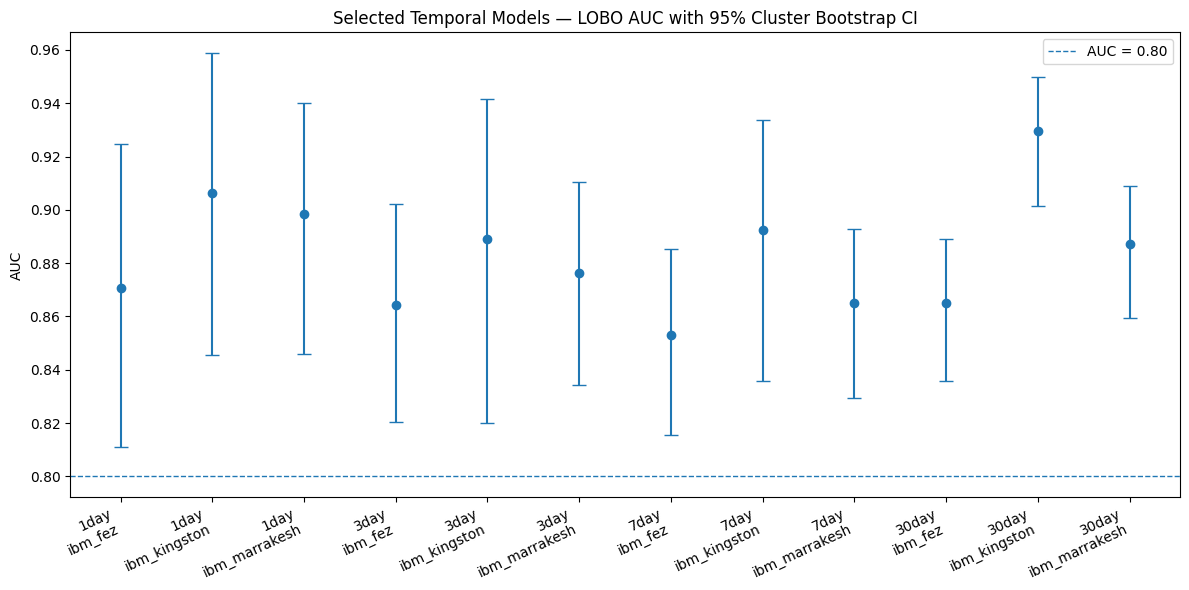

Saved: D:\Downloads\uday projects\ibm_quantum\results\temporal_sweet_spot\figures\temporal_sweet_spot_bootstrap_ci.png


In [13]:

x = np.arange(len(bootstrap_df))
y = bootstrap_df["Observed_AUC"].to_numpy()
lo = bootstrap_df["CI_Lower_95"].to_numpy()
hi = bootstrap_df["CI_Upper_95"].to_numpy()

plt.figure(figsize=(12, 6))
plt.errorbar(x, y, yerr=[y - lo, hi - y], fmt="o", capsize=5)
plt.axhline(0.80, linestyle="--", linewidth=1, label="AUC = 0.80")
plt.xticks(
    x,
    [f"{r.Window}\n{r.Backend}" for r in bootstrap_df.itertuples()],
    rotation=25,
    ha="right",
)
plt.ylabel("AUC")
plt.title("Selected Temporal Models — LOBO AUC with 95% Cluster Bootstrap CI")
plt.legend()
plt.tight_layout()

bootstrap_fig = FIGURES_DIR / "temporal_sweet_spot_bootstrap_ci.png"
plt.savefig(bootstrap_fig, dpi=150)
plt.show()
print("Saved:", bootstrap_fig)


## 14. Prospective Sep-4 / Sep-5 / Sep-6 predictions

For each date/window, the model is trained only on dates strictly before the prediction date, using the algorithm selected by LOBO for that window.

In [14]:

def fit_selected_model(train_df, algorithm):
    if train_df["label"].nunique() < 2:
        raise ValueError(f"{algorithm}: training data contains only one class.")

    params = XGB_PARAMS if algorithm == "XGBoost" else RF_PARAMS
    model = build_model(algorithm, params)
    model.fit(train_df[HIST_FEATURES], train_df["label"])
    return model

def make_ranking(pred_df, model, window_label, prediction_date):
    out = pred_df[
        ["backend", "qubit", "snapshot_date", "T1_us", "T2_us", "readout_error"]
    ].copy()

    out["viability_score"] = model.predict_proba(pred_df[HIST_FEATURES])[:, 1]
    out["viability_rank"] = (
        out.groupby("backend")["viability_score"]
           .rank(method="first", ascending=False)
           .astype(int)
    )
    out["label"] = pred_df["label"].astype(int).to_numpy()
    out["model_name"] = f"temporal_{window_label}"
    out["window_days"] = WINDOWS[window_label]
    out["prediction_date"] = prediction_date

    return out[
        [
            "model_name", "window_days", "prediction_date", "backend", "qubit",
            "viability_score", "viability_rank", "label",
            "T1_us", "T2_us", "readout_error", "snapshot_date"
        ]
    ].sort_values(["backend", "viability_rank"]).reset_index(drop=True)


In [15]:

prospective_rankings = []
prospective_summary = []

for prediction_date in PREDICTION_DATES:
    print("\n" + "=" * 90)
    print("PREDICTION DATE:", prediction_date)
    print("=" * 90)

    pred = prediction_rows(featured, prediction_date)

    for window_label, window_days in WINDOWS.items():
        train, dates_used = select_window(featured, prediction_date, window_days)
        selected_algorithm = lobo_results[window_label]["best_name"]
        model = fit_selected_model(train, selected_algorithm)

        ranking = make_ranking(pred, model, window_label, prediction_date)
        prospective_rankings.append(ranking)

        csv_path = RESULTS_DIR / f"temporal_{window_label}_predictions_{prediction_date}.csv"
        ranking.to_csv(csv_path, index=False)

        prospective_summary.append({
            "prediction_date": prediction_date,
            "Window": window_label,
            "Window_Days": window_days,
            "Selected_Algorithm": selected_algorithm,
            "Training_First_Date": dates_used[0],
            "Training_Last_Date": dates_used[-1],
            "Training_Observed_Dates": len(dates_used),
            "Training_Rows": len(train),
            "Prediction_Rows": len(ranking),
            "Ranking_CSV": str(csv_path),
        })

        print(
            f"{window_label:6s} | {selected_algorithm:12s} | "
            f"train {dates_used[0]} → {dates_used[-1]} | "
            f"rows={len(train):,} | saved={csv_path.name}"
        )

all_predictions_df = pd.concat(prospective_rankings, ignore_index=True)
prospective_summary_df = pd.DataFrame(prospective_summary)

all_predictions_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_all_prospective_predictions.csv",
    index=False,
)
prospective_summary_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_prospective_summary.csv",
    index=False,
)

display(prospective_summary_df)



PREDICTION DATE: 2026-09-04
1day   | RandomForest | train 2026-09-03 → 2026-09-03 | rows=466 | saved=temporal_1day_predictions_2026-09-04.csv
3day   | RandomForest | train 2026-09-01 → 2026-09-03 | rows=1,398 | saved=temporal_3day_predictions_2026-09-04.csv
7day   | RandomForest | train 2026-08-28 → 2026-09-03 | rows=3,262 | saved=temporal_7day_predictions_2026-09-04.csv
30day  | RandomForest | train 2026-08-05 → 2026-09-03 | rows=13,980 | saved=temporal_30day_predictions_2026-09-04.csv

PREDICTION DATE: 2026-09-05
1day   | RandomForest | train 2026-09-04 → 2026-09-04 | rows=466 | saved=temporal_1day_predictions_2026-09-05.csv
3day   | RandomForest | train 2026-09-02 → 2026-09-04 | rows=1,398 | saved=temporal_3day_predictions_2026-09-05.csv
7day   | RandomForest | train 2026-08-29 → 2026-09-04 | rows=3,262 | saved=temporal_7day_predictions_2026-09-05.csv
30day  | RandomForest | train 2026-08-06 → 2026-09-04 | rows=13,980 | saved=temporal_30day_predictions_2026-09-05.csv

PREDICTION DA

,prediction_date,Window,Window_Days,Selected_Algorithm,Training_First_Date,Training_Last_Date,Training_Observed_Dates,Training_Rows,Prediction_Rows,Ranking_CSV
0,2026-09-04,1day,1,RandomForest,2026-09-03,2026-09-03,1,466,466,D:\Downloads\uday projects\ibm_quantum\results...
1,2026-09-04,3day,3,RandomForest,2026-09-01,2026-09-03,3,1398,466,D:\Downloads\uday projects\ibm_quantum\results...
2,2026-09-04,7day,7,RandomForest,2026-08-28,2026-09-03,7,3262,466,D:\Downloads\uday projects\ibm_quantum\results...
3,2026-09-04,30day,30,RandomForest,2026-08-05,2026-09-03,30,13980,466,D:\Downloads\uday projects\ibm_quantum\results...
4,2026-09-05,1day,1,RandomForest,2026-09-04,2026-09-04,1,466,466,D:\Downloads\uday projects\ibm_quantum\results...
5,2026-09-05,3day,3,RandomForest,2026-09-02,2026-09-04,3,1398,466,D:\Downloads\uday projects\ibm_quantum\results...
6,2026-09-05,7day,7,RandomForest,2026-08-29,2026-09-04,7,3262,466,D:\Downloads\uday projects\ibm_quantum\results...
7,2026-09-05,30day,30,RandomForest,2026-08-06,2026-09-04,30,13980,466,D:\Downloads\uday projects\ibm_quantum\results...
8,2026-09-06,1day,1,RandomForest,2026-09-05,2026-09-05,1,466,466,D:\Downloads\uday projects\ibm_quantum\results...
9,2026-09-06,3day,3,RandomForest,2026-09-03,2026-09-05,3,1398,466,D:\Downloads\uday projects\ibm_quantum\results...


## 15. Inspect the actual Sep-6 predicted qubits

In [16]:

sep6_predictions = all_predictions_df[
    all_predictions_df["prediction_date"] == SEP6_DATE
].copy()

for window_label in WINDOWS:
    print("\n" + "=" * 70)
    print(f"TEMPORAL {window_label} — SEP-6")
    print("=" * 70)

    display(
        sep6_predictions[
            sep6_predictions["model_name"] == f"temporal_{window_label}"
        ]
        .sort_values(["backend", "viability_rank"])
        .groupby("backend", group_keys=False)
        .head(10)
        [[
            "backend", "qubit", "viability_score", "viability_rank",
            "T1_us", "T2_us", "readout_error"
        ]]
    )



TEMPORAL 1day — SEP-6


,backend,qubit,viability_score,viability_rank,T1_us,T2_us,readout_error
3728,ibm_fez,71,0.988068,1,207.580,65.8707,0.006348
3729,ibm_fez,37,0.988006,2,123.117,150.9650,0.009033
3730,ibm_fez,36,0.987442,3,154.765,149.6090,0.008545
3731,ibm_fez,21,0.986979,4,143.430,126.2950,0.062988
3732,ibm_fez,123,0.986869,5,127.399,97.9030,0.005127
3733,ibm_fez,4,0.985844,6,158.109,142.4810,0.002686
3734,ibm_fez,13,0.985522,7,308.361,194.4740,0.010986
3735,ibm_fez,92,0.984442,8,127.698,158.7030,0.029907
3736,ibm_fez,136,0.984207,9,74.108,80.7748,0.005493
3737,ibm_fez,154,0.983284,10,170.346,121.7590,0.005371



TEMPORAL 3day — SEP-6


,backend,qubit,viability_score,viability_rank,T1_us,T2_us,readout_error
4194,ibm_fez,2,0.971367,1,54.4646,84.4745,0.006348
4195,ibm_fez,21,0.962439,2,143.4300,126.2950,0.062988
4196,ibm_fez,23,0.957234,3,127.9760,34.2213,0.005737
4197,ibm_fez,15,0.955577,4,305.5790,228.7140,0.040527
4198,ibm_fez,13,0.953882,5,308.3610,194.4740,0.010986
4199,ibm_fez,141,0.952692,6,167.3060,90.6258,0.005127
4200,ibm_fez,71,0.952095,7,207.5800,65.8707,0.006348
4201,ibm_fez,123,0.951674,8,127.3990,97.9030,0.005127
4202,ibm_fez,147,0.949064,9,139.4870,127.2040,0.007446
4203,ibm_fez,10,0.949039,10,133.4390,139.3000,0.003052



TEMPORAL 7day — SEP-6


,backend,qubit,viability_score,viability_rank,T1_us,T2_us,readout_error
4660,ibm_fez,2,0.959123,1,54.4646,84.4745,0.006348
4661,ibm_fez,13,0.957347,2,308.3610,194.4740,0.010986
4662,ibm_fez,15,0.945232,3,305.5790,228.7140,0.040527
4663,ibm_fez,21,0.938888,4,143.4300,126.2950,0.062988
4664,ibm_fez,23,0.928583,5,127.9760,34.2213,0.005737
4665,ibm_fez,28,0.923280,6,125.6570,105.7040,0.006348
4666,ibm_fez,75,0.923212,7,92.1280,94.4002,0.005249
4667,ibm_fez,3,0.922037,8,70.8910,70.5501,0.042114
4668,ibm_fez,10,0.921808,9,133.4390,139.3000,0.003052
4669,ibm_fez,4,0.917625,10,158.1090,142.4810,0.002686



TEMPORAL 30day — SEP-6


,backend,qubit,viability_score,viability_rank,T1_us,T2_us,readout_error
5126,ibm_fez,13,0.956503,1,308.3610,194.4740,0.010986
5127,ibm_fez,15,0.938425,2,305.5790,228.7140,0.040527
5128,ibm_fez,2,0.933596,3,54.4646,84.4745,0.006348
5129,ibm_fez,3,0.905664,4,70.8910,70.5501,0.042114
5130,ibm_fez,23,0.904173,5,127.9760,34.2213,0.005737
5131,ibm_fez,21,0.900025,6,143.4300,126.2950,0.062988
5132,ibm_fez,20,0.897673,7,201.6250,53.5964,0.007812
5133,ibm_fez,75,0.892160,8,92.1280,94.4002,0.005249
5134,ibm_fez,1,0.889931,9,201.6540,176.4910,0.014404
5135,ibm_fez,28,0.887716,10,125.6570,105.7040,0.006348


## 16. Save Sep-6 hardware-selection CSVs

The hardware project should select the highest-ranked **topology-valid connected 3-qubit group** from these candidates. This notebook does not submit QPU jobs.

In [17]:

HARDWARE_DIR = RESULTS_DIR / "hardware_selection"
HARDWARE_DIR.mkdir(parents=True, exist_ok=True)

sep6_combined_path = HARDWARE_DIR / "sep6_all_temporal_model_predictions.csv"
sep6_predictions.sort_values(
    ["model_name", "backend", "viability_rank"]
).to_csv(sep6_combined_path, index=False)

top1_parts = []
top10_parts = []

for window_label in WINDOWS:
    model_name = f"temporal_{window_label}"
    x = sep6_predictions[sep6_predictions["model_name"] == model_name].copy()

    top1 = (
        x.sort_values(["backend", "viability_rank"])
         .groupby("backend", group_keys=False)
         .head(1)
         .copy()
    )
    top10 = (
        x.sort_values(["backend", "viability_rank"])
         .groupby("backend", group_keys=False)
         .head(10)
         .copy()
    )

    top1.to_csv(HARDWARE_DIR / f"{model_name}_sep6_top1_per_backend.csv", index=False)
    top10.to_csv(HARDWARE_DIR / f"{model_name}_sep6_top10_per_backend.csv", index=False)

    top1_parts.append(top1)
    top10_parts.append(top10)

hardware_top1 = pd.concat(top1_parts, ignore_index=True)
hardware_top10 = pd.concat(top10_parts, ignore_index=True)

hardware_top1.to_csv(HARDWARE_DIR / "sep6_all_models_top1_per_backend.csv", index=False)
hardware_top10.to_csv(HARDWARE_DIR / "sep6_all_models_top10_per_backend.csv", index=False)

display(
    hardware_top1[
        ["model_name", "backend", "qubit", "viability_score", "viability_rank"]
    ].sort_values(["backend", "model_name"])
)


,model_name,backend,qubit,viability_score,viability_rank
0,temporal_1day,ibm_fez,71,0.988068,1
9,temporal_30day,ibm_fez,13,0.956503,1
3,temporal_3day,ibm_fez,2,0.971367,1
6,temporal_7day,ibm_fez,2,0.959123,1
1,temporal_1day,ibm_kingston,17,0.990510,1
10,temporal_30day,ibm_kingston,149,0.964277,1
4,temporal_3day,ibm_kingston,50,0.980193,1
7,temporal_7day,ibm_kingston,21,0.980871,1
2,temporal_1day,ibm_marrakesh,134,0.979783,1
11,temporal_30day,ibm_marrakesh,112,0.958027,1


## 17. Temporal ranking stability across Sep-4 → Sep-5 → Sep-6

In [18]:

def top10_set(df, model_name, backend, prediction_date):
    x = df[
        (df["model_name"] == model_name)
        & (df["backend"] == backend)
        & (df["prediction_date"] == prediction_date)
    ].sort_values("viability_rank").head(10)
    return set(x["qubit"].astype(int))

stability_rows = []

for window_label in WINDOWS:
    model_name = f"temporal_{window_label}"

    for backend in sorted(sep6_predictions["backend"].unique()):
        sets = {
            d: top10_set(all_predictions_df, model_name, backend, d)
            for d in PREDICTION_DATES
        }

        for d1, d2 in combinations(PREDICTION_DATES, 2):
            a, b = sets[d1], sets[d2]
            union = a | b
            stability_rows.append({
                "model_name": model_name,
                "backend": backend,
                "date_1": d1,
                "date_2": d2,
                "top10_intersection": len(a & b),
                "top10_jaccard": len(a & b) / len(union) if union else np.nan,
            })

stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_ranking_stability.csv",
    index=False,
)
display(stability_df.round(4))


,model_name,backend,date_1,date_2,top10_intersection,top10_jaccard
0,temporal_1day,ibm_fez,2026-09-04,2026-09-05,4,0.2500
1,temporal_1day,ibm_fez,2026-09-04,2026-09-06,3,0.1765
2,temporal_1day,ibm_fez,2026-09-05,2026-09-06,3,0.1765
3,temporal_1day,ibm_kingston,2026-09-04,2026-09-05,3,0.1765
4,temporal_1day,ibm_kingston,2026-09-04,2026-09-06,3,0.1765
5,temporal_1day,ibm_kingston,2026-09-05,2026-09-06,4,0.2500
6,temporal_1day,ibm_marrakesh,2026-09-04,2026-09-05,5,0.3333
7,temporal_1day,ibm_marrakesh,2026-09-04,2026-09-06,6,0.4286
8,temporal_1day,ibm_marrakesh,2026-09-05,2026-09-06,4,0.2500
9,temporal_3day,ibm_fez,2026-09-04,2026-09-05,5,0.3333


## 18. Save exactly four final Sep-6 model artifacts

In [19]:

final_model_metadata = []

for window_label, window_days in WINDOWS.items():
    train, dates_used = select_window(featured, SEP6_DATE, window_days)
    selected_algorithm = lobo_results[window_label]["best_name"]
    model = fit_selected_model(train, selected_algorithm)

    filename = f"temporal_{window_label}_final_sep6.pkl"
    model_path = MODELS_DIR / filename

    with open(model_path, "wb") as f:
        pickle.dump(model, f)

    lobo = lobo_results[window_label]["best_results"]

    metadata = {
        "model_name": f"Temporal_{window_label}",
        "model_file": filename,
        "window_days": window_days,
        "training_first_date": str(dates_used[0]),
        "training_last_date": str(dates_used[-1]),
        "prediction_date": str(SEP6_DATE),
        "selected_algorithm": selected_algorithm,
        "training_rows": int(len(train)),
        "training_viable_rate": float(train["label"].mean()),
        "features": HIST_FEATURES,
        "label_thresholds": {
            "T1_us": T1_THRESH,
            "T2_us": T2_THRESH,
            "readout_error": RE_THRESH,
        },
        "feature_source": "prior_sessions_only_shift_expand",
        "lobo_results": lobo.round(6).to_dict(orient="records"),
        "lobo_mean_auc": float(lobo["AUC"].mean()),
        "lobo_min_auc": float(lobo["AUC"].min()),
    }

    metadata_path = RESULTS_DIR / f"temporal_{window_label}_final_sep6_metadata.json"
    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    final_model_metadata.append(metadata)

final_models_df = pd.DataFrame(final_model_metadata)
final_models_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_final_sep6_models.csv",
    index=False,
)

display(
    final_models_df[[
        "model_name", "selected_algorithm", "window_days",
        "training_first_date", "training_last_date",
        "training_rows", "lobo_mean_auc", "lobo_min_auc"
    ]].round(4)
)


,model_name,selected_algorithm,window_days,training_first_date,training_last_date,training_rows,lobo_mean_auc,lobo_min_auc
0,Temporal_1day,RandomForest,1,2026-09-05,2026-09-05,466,0.8918,0.8706
1,Temporal_3day,RandomForest,3,2026-09-03,2026-09-05,1398,0.8766,0.8644
2,Temporal_7day,RandomForest,7,2026-08-30,2026-09-05,3262,0.8701,0.8531
3,Temporal_30day,RandomForest,30,2026-08-07,2026-09-05,13980,0.8939,0.8649


## 19. Final audit

In [20]:

assert set(PREDICTION_DATES).issubset(set(raw["snapshot_date"].unique()))
assert list(WINDOWS.keys()) == ["1day", "3day", "7day", "30day"]
assert len(all_lobo_df) == 4 * 2 * 3
assert len(best_summary_df) == 4
assert best_summary_df["Selected_Algorithm"].isin(["XGBoost", "RandomForest"]).all()
assert sep6_predictions["model_name"].nunique() == 4
assert set(sep6_predictions["backend"].unique()) == EXPECTED_BACKENDS

final_pickles = sorted(MODELS_DIR.glob("temporal_*_final_sep6.pkl"))
assert len(final_pickles) == 4, final_pickles

assert not any(
    c in {"T1_us", "T2_us", "readout_error"} for c in HIST_FEATURES
)

print("=" * 90)
print("FINAL AUDIT PASSED")
print("=" * 90)
print("LOBO result rows:", len(all_lobo_df))
print("Bootstrap CI rows:", len(bootstrap_df))
print("Prospective prediction rows:", len(all_predictions_df))
print("Sep-6 ranking rows:", len(sep6_predictions))
print("Final pickle files:", len(final_pickles))
print("\nFinal models:")
for p in final_pickles:
    print(" ", p)
print("\nPrimary hardware input:")
print(" ", sep6_combined_path)


FINAL AUDIT PASSED
LOBO result rows: 24
Bootstrap CI rows: 12
Prospective prediction rows: 5592
Sep-6 ranking rows: 1864
Final pickle files: 4

Final models:
  D:\Downloads\uday projects\ibm_quantum\models\temporal_sweet_spot\temporal_1day_final_sep6.pkl
  D:\Downloads\uday projects\ibm_quantum\models\temporal_sweet_spot\temporal_30day_final_sep6.pkl
  D:\Downloads\uday projects\ibm_quantum\models\temporal_sweet_spot\temporal_3day_final_sep6.pkl
  D:\Downloads\uday projects\ibm_quantum\models\temporal_sweet_spot\temporal_7day_final_sep6.pkl

Primary hardware input:
  D:\Downloads\uday projects\ibm_quantum\results\temporal_sweet_spot\hardware_selection\sep6_all_temporal_model_predictions.csv


# Output map

### Results

```text
results/temporal_sweet_spot/
├── temporal_sweet_spot_lobo_all_results.csv
├── temporal_sweet_spot_algorithm_comparison.csv
├── temporal_sweet_spot_selected_window_summary.csv
├── temporal_sweet_spot_bootstrap_ci.csv
├── temporal_sweet_spot_prospective_summary.csv
├── temporal_sweet_spot_all_prospective_predictions.csv
├── temporal_sweet_spot_ranking_stability.csv
└── figures/
    ├── 1day_selected_lobo_roc.png
    ├── 3day_selected_lobo_roc.png
    ├── 7day_selected_lobo_roc.png
    ├── 30day_selected_lobo_roc.png
    └── temporal_sweet_spot_bootstrap_ci.png
```

### Sep-6 hardware input

```text
results/temporal_sweet_spot/hardware_selection/
├── sep6_all_temporal_model_predictions.csv
├── sep6_all_models_top1_per_backend.csv
├── sep6_all_models_top10_per_backend.csv
├── temporal_1day_sep6_top10_per_backend.csv
├── temporal_3day_sep6_top10_per_backend.csv
├── temporal_7day_sep6_top10_per_backend.csv
└── temporal_30day_sep6_top10_per_backend.csv
```

### Final models

```text
models/temporal_sweet_spot/
├── temporal_1day_final_sep6.pkl
├── temporal_3day_final_sep6.pkl
├── temporal_7day_final_sep6.pkl
└── temporal_30day_final_sep6.pkl
```

**Next step:** audit these Sep-6 temporal rankings against the actual Sep-6 Model A/B/C rankings, then select topology-valid 3-qubit groups in the separate `ibm_circuits` project. No QPU jobs are submitted by this notebook.